![JohnSnowLabs](https://nlp.johnsnowlabs.com/assets/images/logo.png)

# Document Layout Analyze
Let's explore Layout Analysis & OCR


In [5]:
secret = ""
license = ""
version = secret.split("-")[0]
spark_ocr_jar_path = "../../../target/scala-2.12"

In [3]:
# install from PYPI using secret
#%pip install spark-ocr==$version --extra-index-url=https://pypi.johnsnowlabs.com/$secret --upgrade

## Initialize Spark Session

In [6]:
from pyspark.sql import SparkSession
from sparkocr import start
import os

if license:
    os.environ['SPARK_OCR_LICENSE'] = license

spark = start(secret=secret, jar_path=spark_ocr_jar_path)
spark

Spark version: 3.5.1
Spark NLP version: 7.0.0
Spark NLP for Healthcare version: 7.0.0
Spark OCR version: 7.0.0



In [7]:
import pkg_resources

from pyspark.ml import PipelineModel
import pyspark.sql.functions as f

from sparkocr import start
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import *
from sparkocr.metrics import score

## Load Sample PDF


    Image #0:
    Origin: file:/home/jose/spark-ocr/notebooks/trainings_october_2026/mixed_formats/forms.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


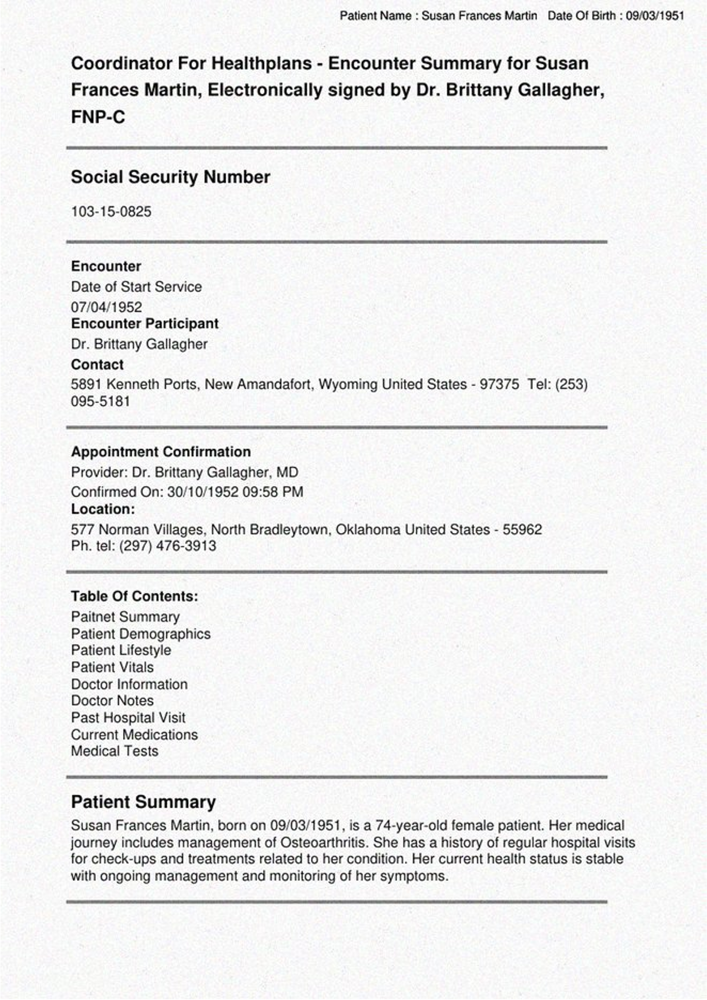

Empty image

    Image #2:
    Origin: file:/home/jose/spark-ocr/notebooks/trainings_october_2026/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


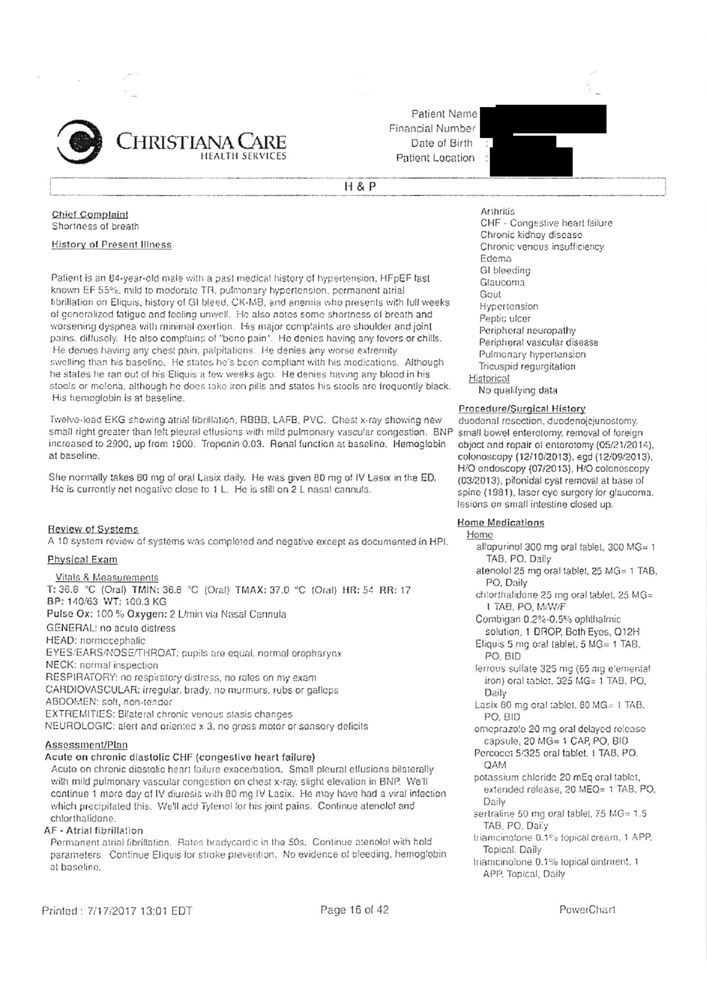


    Image #3:
    Origin: file:/home/jose/spark-ocr/notebooks/trainings_october_2026/mixed_formats/h_and_p.pdf
    Resolution: 300 dpi
    Width: 2480 px
    Height: 3507 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


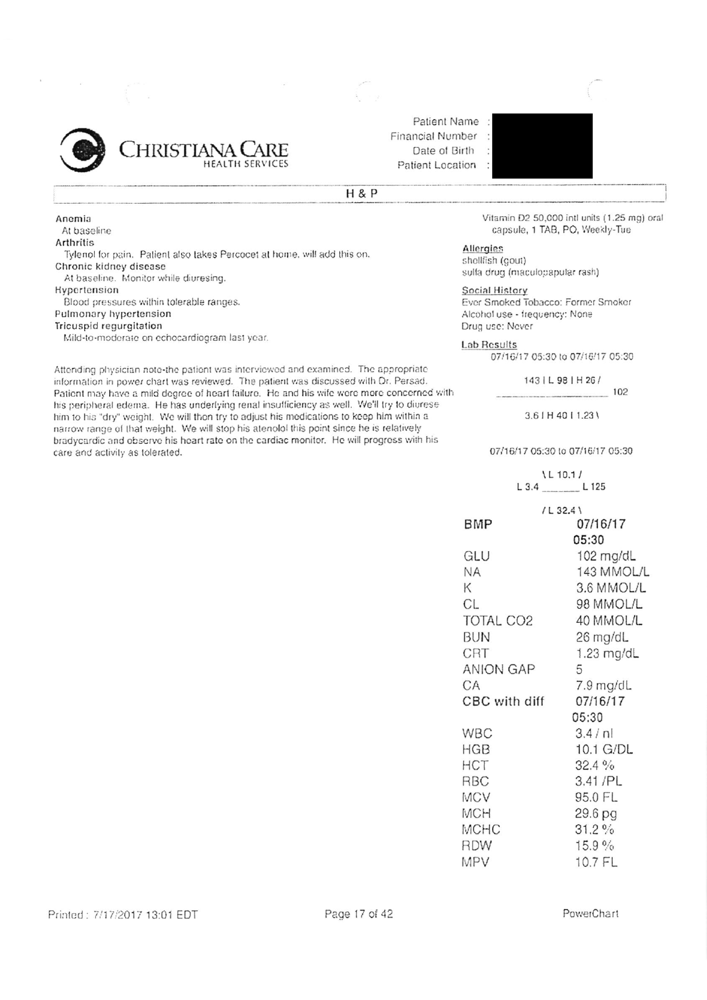


    Image #4:
    Origin: file:/home/jose/spark-ocr/notebooks/trainings_october_2026/mixed_formats/report.pdf
    Resolution: 300 dpi
    Width: 4241 px
    Height: 2650 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


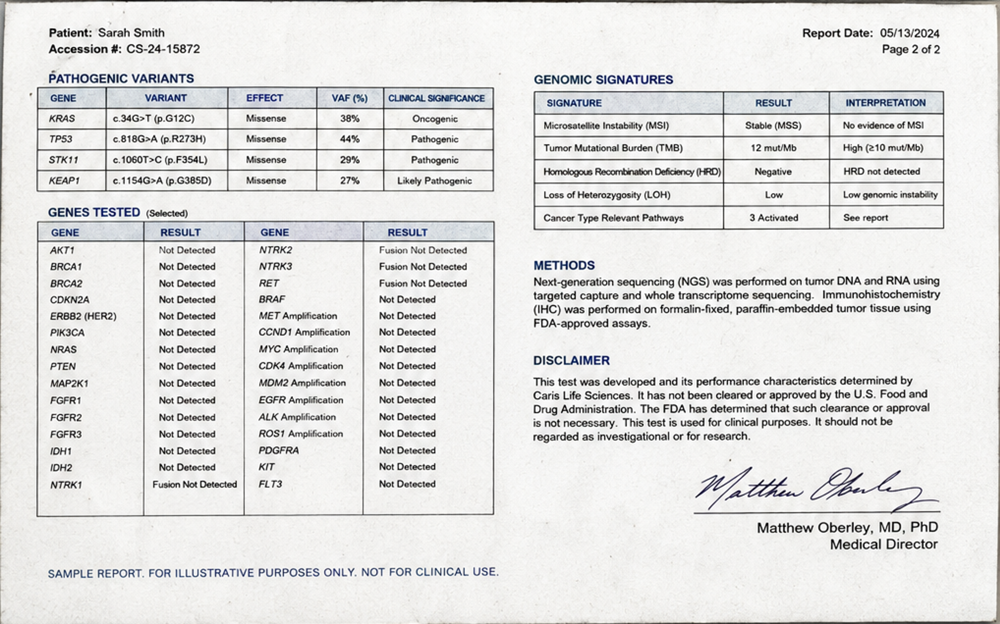

In [8]:
from pyspark.ml import PipelineModel
import pyspark.sql.functions as f
from sparkocr.transformers import *
from sparkocr.enums import *
from sparkocr.utils import display_images

pdf_path = "../mixed_formats"
pdf_df = spark.read.format("binaryFile").load(pdf_path)
pdf_to_image = PdfToImage() \
    .setImageType(ImageType.TYPE_3BYTE_BGR)

display_images(pdf_to_image.transform(pdf_df), "image")

## Load Pipeline


In [9]:
dit_layout = DocumentLayoutAnalyzer \
    .pretrained("publaynet_dit_base_mrcnn_jsl", "en", "clinical/ocr") \
    .setInputCol("image") \
    .setOutputCol("regions") \
    .setScoreThreshold(0.5)

splitter = ImageSplitRegions() \
    .setInputCol("image") \
    .setInputRegionsCol("regions") \
    .setOutputCol("layout_element") \
    .setDropCols("image") \
    .setImageType(ImageType.TYPE_3BYTE_BGR)

# Extract text from image
ocr = ImageToText() \
    .setInputCol("layout_element") \
    .setOutputCol("text") \
    .setIgnoreResolution(False) \
    .setPageIteratorLevel(PageIteratorLevel.SYMBOL) \
    .setPageSegMode(PageSegmentationMode.SPARSE_TEXT) \
    .setConfidenceThreshold(70)

draw_regions = ImageDrawRegions() \
    .setInputCol("image") \
    .setInputRegionsCol("regions") \
    .setOutputCol("image_with_regions") \
    .setRectColor(Color.green)

pipeline = PipelineModel(stages=[
    pdf_to_image,
    dit_layout,
    splitter,
    ocr
])

publaynet_dit_base_mrcnn_jsl download started this may take some time.
Approximate size to download 401.2 MB


23:15:53, ERROR KeyboardInterrupt while sending command.
Traceback (most recent call last):
  File "/home/jose/.local/lib/python3.10/site-packages/py4j/java_gateway.py", line 1038, in send_command
    response = connection.send_command(command)
  File "/home/jose/.local/lib/python3.10/site-packages/py4j/clientserver.py", line 511, in send_command
    answer = smart_decode(self.stream.readline()[:-1])
  File "/usr/local/lib/python3.10/socket.py", line 705, in readinto
    return self._sock.recv_into(b)
KeyboardInterrupt
23:15:53, INFO Closing down clientserver connection


KeyboardInterrupt: 

## Call the pipeline

In [8]:
it = pipeline.transform(pdf_df).select("text").cache().toLocalIterator()

In [9]:
print(next(it).text)


gical Pathology (continued) Final result
Order:
1. IgA nephropathy with secondary focal segmental glomerulosclerosis;
see comment.
2. Ultrastructural evidence of attenuated (thin) glomerular basement
membranes; see comment.
3. Moderate chronicity.
COMMENT:
Light Microscopy (LM): The specimen consists of 4 core of renal
cortical tissue with up to 16 glomeruli per section, 8 of which are
globally sclerotic (predominantly “disappearing” pattern). At least 3
glomeruli show classic features of FSGS> Elsewhere, the glomerular
capillary lumina are patent; no glomerular endocapillary or
extracapillary hypercellularity is seen. The glomerular capillary walls
appear to be of normal thickness. Mild diffuse mesangial matrix
accumulation and increase in cellularity is seen. The tubulointerstitium
shows ~40% IFTA. The arteries and arterioles are unremarkable. No TMA
or vasculitis is present.
Immunofluorescence Microscopy (IF): Frozen sections contain renal
cortical tissue with 4 glomeruli present. 

In [10]:
print(next(it).text)


3. Moderate chronicity.


In [11]:
print(next(it).text)


Surgical Pathology (continued) Final result
Order: 681800952
1. IgA nephropathy with secondary focal segmental glomerulosclerosis;
see comment.
2. Ultrastructural evidence of attenuated (thin) glomerular basement
membranes; see comment.


## Show the regions


    Image #0:
    Origin: file:/home/jose/spark-ocr/notebooks/panoramic/Example12_Redacted.pdf
    Resolution: 300 dpi
    Width: 2550 px
    Height: 3299 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


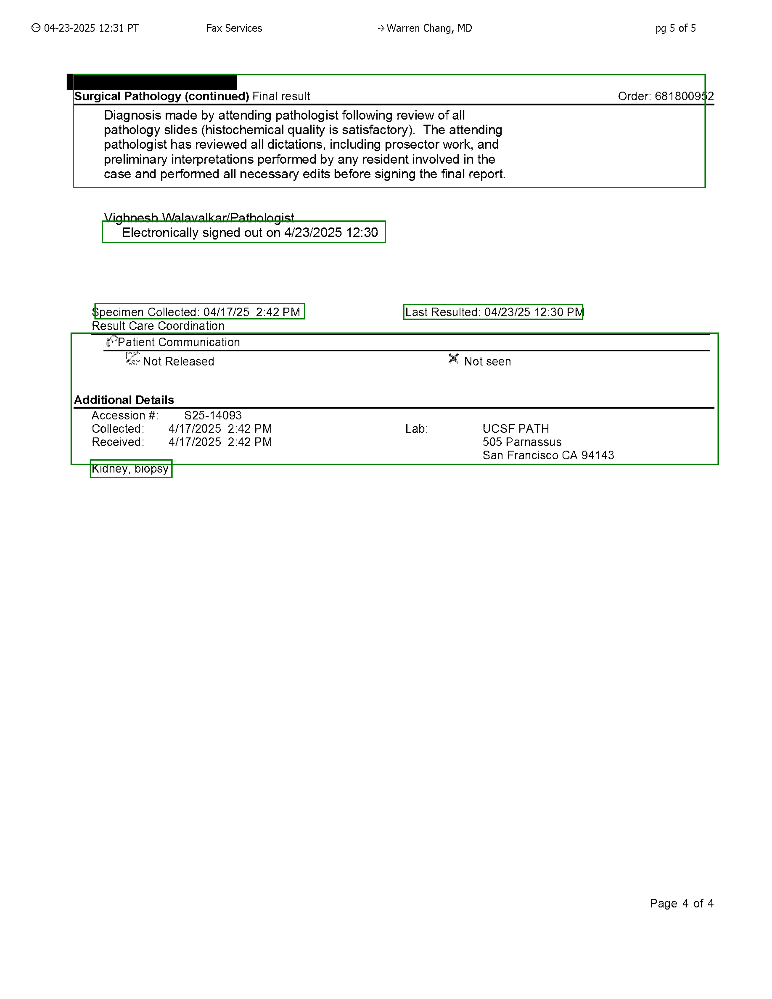


    Image #1:
    Origin: file:/home/jose/spark-ocr/notebooks/panoramic/Example12_Redacted.pdf
    Resolution: 300 dpi
    Width: 2550 px
    Height: 3299 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


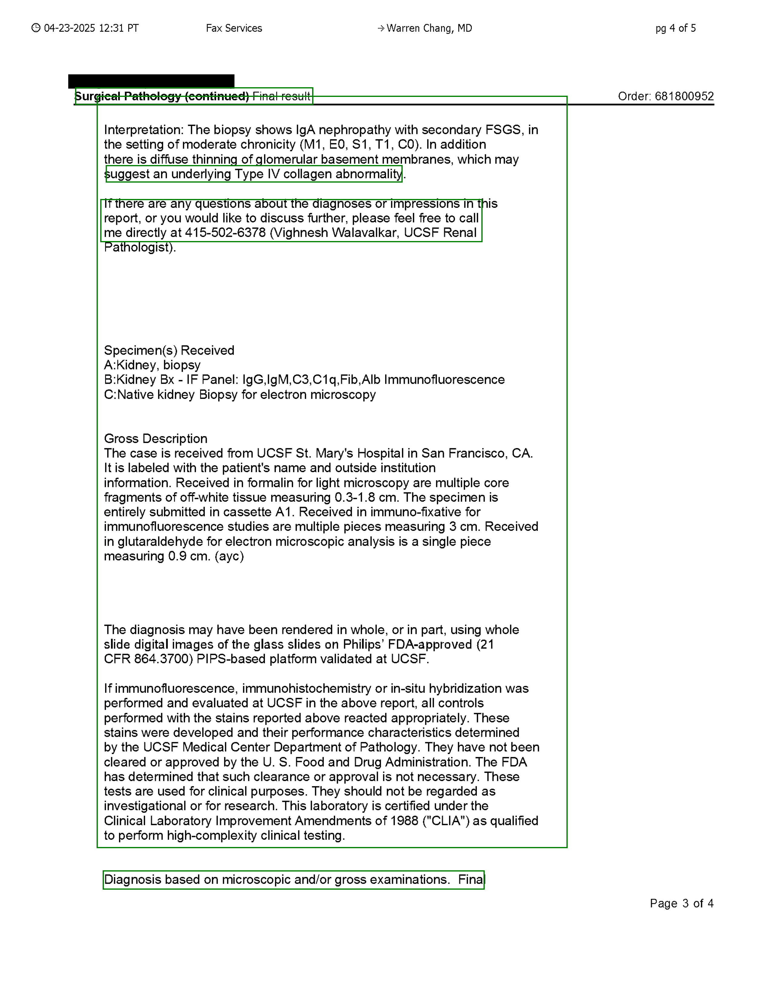


    Image #2:
    Origin: file:/home/jose/spark-ocr/notebooks/panoramic/Example12_Redacted.pdf
    Resolution: 300 dpi
    Width: 2550 px
    Height: 3299 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


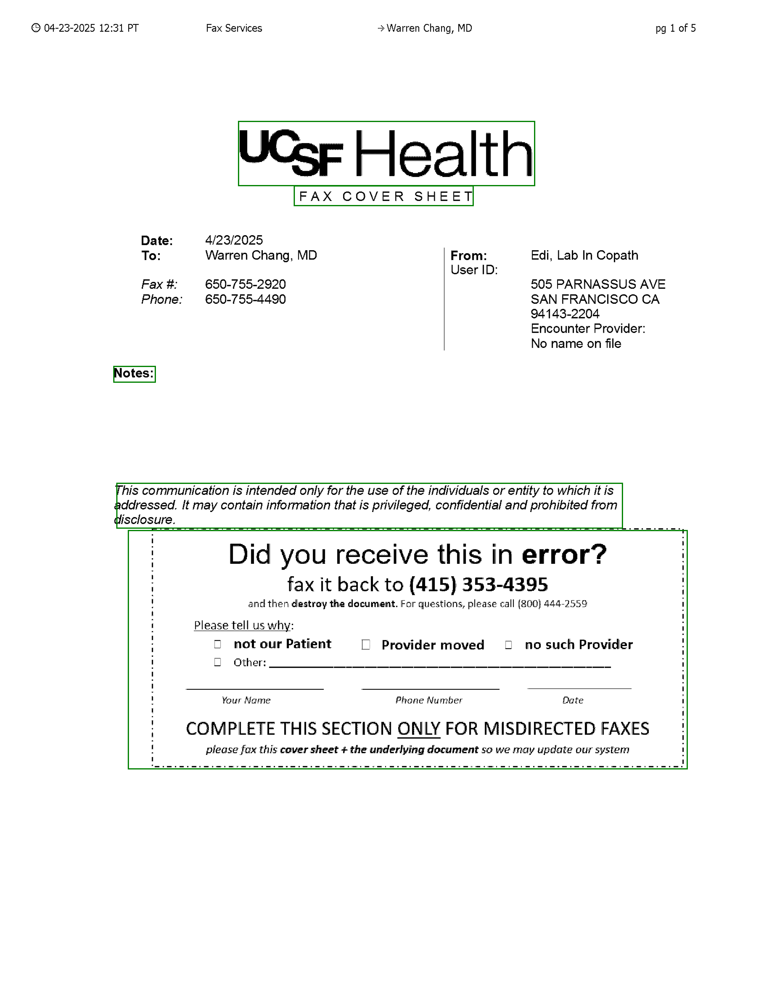


    Image #3:
    Origin: file:/home/jose/spark-ocr/notebooks/panoramic/Example12_Redacted.pdf
    Resolution: 300 dpi
    Width: 2550 px
    Height: 3299 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


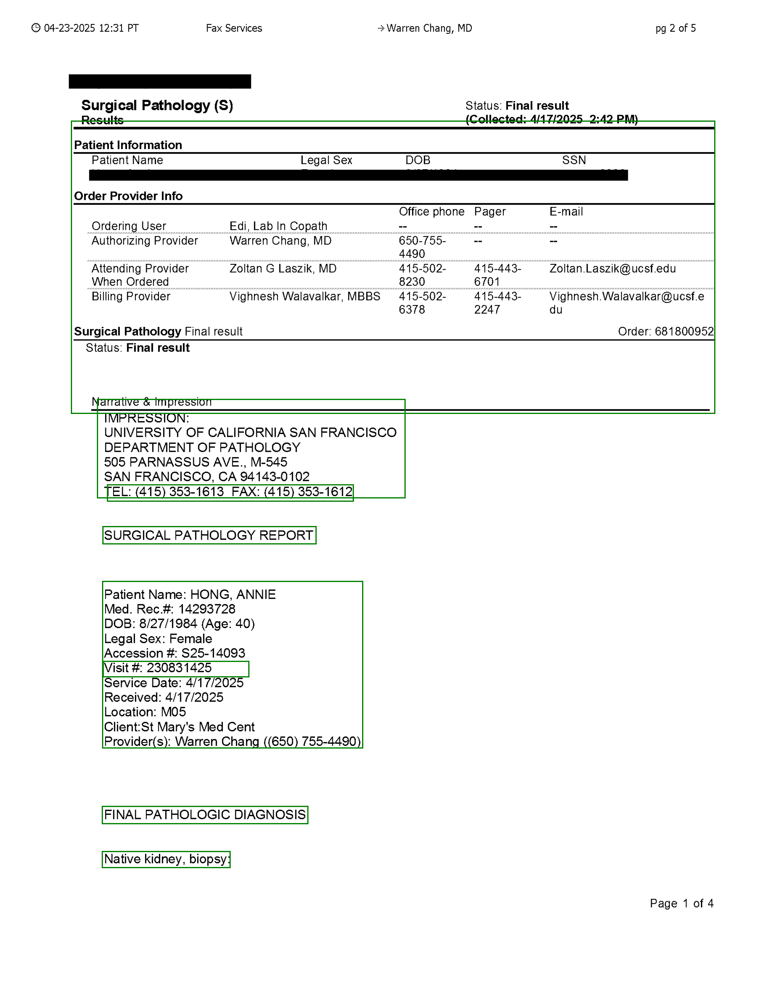


    Image #4:
    Origin: file:/home/jose/spark-ocr/notebooks/panoramic/Example12_Redacted.pdf
    Resolution: 300 dpi
    Width: 2550 px
    Height: 3299 px
    Mode: ImageType.TYPE_3BYTE_BGR
    Number of channels: 3


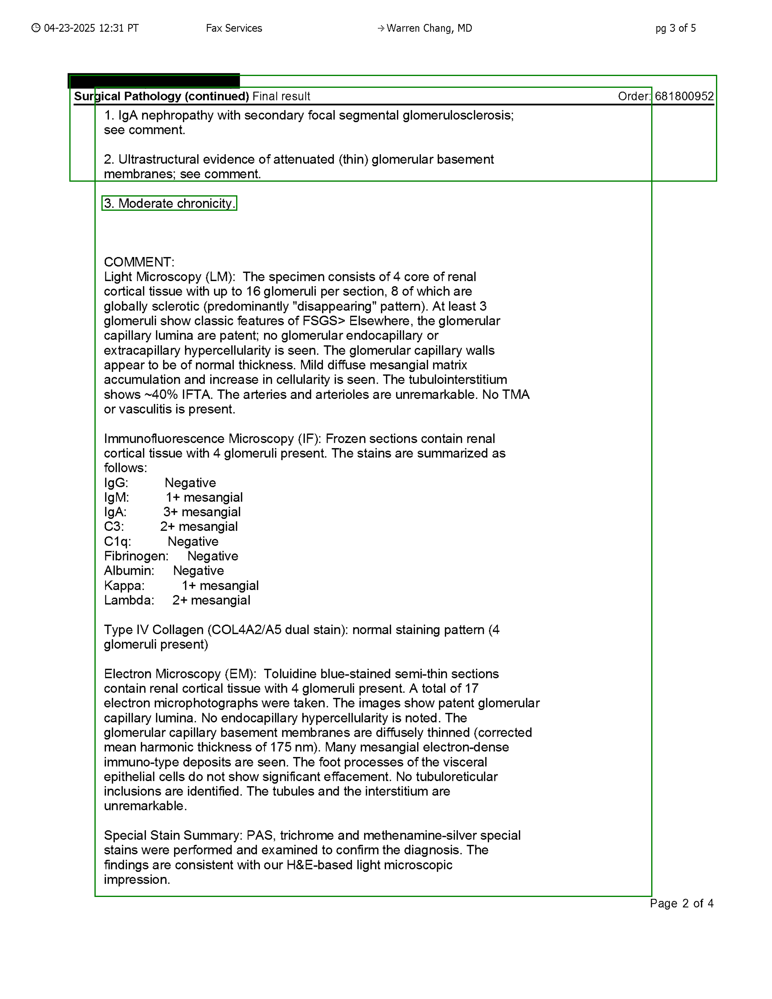

In [12]:
pipeline = PipelineModel(stages=[pdf_to_image, dit_layout, draw_regions])
result = pipeline.transform(pdf_df).cache()
display_images(result, "image_with_regions")